In [1]:
# --- 1.0 environment ------------------------------------------------------
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.unicode_minus": False,
})

In [2]:
# --- 1.0 open the file ----------------------------------------------------
CH4_FILE = os.path.join(
    DATA_DIR, "200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
ds_ch4 = xr.open_dataset(CH4_FILE, decode_times=True)
print(ds_ch4)

<xarray.Dataset> Size: 54MB
Dimensions:                  (time: 210, bnds: 2, lat: 36, lon: 72, pressure: 10)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 .....
  * lat                      (lat) float64 288B -87.5 -82.5 -77.5 ... 82.5 87.5
  * lon                      (lon) float64 576B -177.5 -172.5 ... 172.5 177.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] 3kB ...
    lat_bnds                 (lat, bnds) float64 576B ...
    lon_bnds                 (lon, bnds) float64 1kB ...
    pre                      (pressure) float64 80B ...
    pre_bnds                 (pressure, bnds) float64 160B ...
    land_fraction            (lat, lon) float64 21kB ...
    xch4                     (time, lat, lon) float32 2MB ...
    xch4_nobs                (time, lat, lon) float64 4MB ...
    xch4_stderr              (time, lat, lon) float32 2MB ...
    xch4_stddev              (tim

In [3]:
# --- 1.0 decode xch4: unit conversion and fill value ---------------------
# xch4 is a mole fraction (1 = 1 mol/mol), so ppb needs a factor 1e9.
# Cells without a retrieval carry 1e20; it is not flagged as _FillValue in the
# file, therefore netCDF4 does not mask it automatically and it has to be
# removed by hand before any average is taken.
xch4 = ds_ch4["xch4"]
print("dtype      :", xch4.dtype)
print("raw min/max:", float(xch4.min()), float(xch4.max()))
print("fill cells :", int((xch4.values >= 1e19).sum()), "of", xch4.size)

xch4_ppb = xch4.where(xch4 < 1e19) * 1e9
xch4_ppb.name = "xch4"
xch4_ppb.attrs["units"] = "ppb"

print("valid min/max :", round(float(xch4_ppb.min()), 2),
      round(float(xch4_ppb.max()), 2), "ppb")
print("valid fraction:", round(float((~np.isnan(xch4_ppb)).mean()), 4))

lat = xch4_ppb["lat"]
lon = xch4_ppb["lon"]
time = xch4_ppb["time"]
print("time span     :", str(time.values[0])[:10], "->", str(time.values[-1])[:10],
      " n =", time.size)
print("grid          :", lat.size, "lat x", lon.size, "lon, spacing",
      float(lat[1] - lat[0]), "deg")

dtype      : float32
raw min/max: 1.5669854747102363e-06 1.0000000200408773e+20
fill cells : 391920 of 544320
valid min/max : 1566.99 1999.48 ppb
valid fraction: 0.28
time span     : 2003-01-16 -> 2020-06-16  n = 210
grid          : 36 lat x 72 lon, spacing 5.0 deg


In [4]:
# --- 1.0 area weights -----------------------------------------------------
# A 5x5 degree cell covers cos(lat) times less area than one at the equator, so
# an unweighted mean would overweight the polar rows.  cos(lat) is the exact
# area factor of a regular lat-lon grid.
weights = np.cos(np.deg2rad(lat))
print("weight at  0 deg:", round(float(weights.sel(lat=0, method="nearest")), 3))
print("weight at 85 deg:", round(float(weights.sel(lat=85, method="nearest")), 3))

weight at  0 deg: 0.999
weight at 85 deg: 0.044


In [5]:
# --- 1.0 coastline for the maps ------------------------------------------
# cartopy is not installed in this environment, so the 110 m Natural Earth
# coastline was pre-converted once into a plain (N,2) array with NaN gaps.
COAST_FILE = os.path.join(DATA_DIR, "coastline_110m.npz")
_coast = np.load(COAST_FILE)["xy"] if os.path.exists(COAST_FILE) else None


def add_coast(ax, lw=0.5, color="0.25"):
    """Draw the coastline polylines on a lat-lon axes."""
    if _coast is None:
        return
    ax.plot(_coast[:, 0], _coast[:, 1], lw=lw, color=color, zorder=3)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)


print("coastline loaded:", _coast is not None, "points:",
      None if _coast is None else len(_coast))

coastline loaded: True points: 5262


In [6]:
# --- 1.1 methane climatology for each month ------------------------------
# Group the 210 monthly fields by calendar month and average over time.
clim = xch4_ppb.groupby("time.month").mean("time", skipna=True)
print("climatology shape:", clim.shape, "dims:", clim.dims)
print("global min/max   :", round(float(clim.min()), 1),
      round(float(clim.max()), 1), "ppb")
print("monthly global mean of the climatology:")
for m in range(1, 13):
    v = float(clim.sel(month=m).weighted(weights).mean())
    print("   month %2d : %7.2f ppb" % (m, v))

climatology shape: (12, 36, 72) dims: ('month', 'lat', 'lon')
global min/max   : 1576.9 1904.1 ppb
monthly global mean of the climatology:
   month  1 : 1761.59 ppb
   month  2 : 1768.06 ppb
   month  3 : 1774.00 ppb
   month  4 : 1784.52 ppb
   month  5 : 1787.30 ppb
   month  6 : 1786.25 ppb
   month  7 : 1783.70 ppb
   month  8 : 1786.78 ppb
   month  9 : 1783.69 ppb
   month 10 : 1774.70 ppb


   month 11 : 1767.66 ppb
   month 12 : 1765.88 ppb


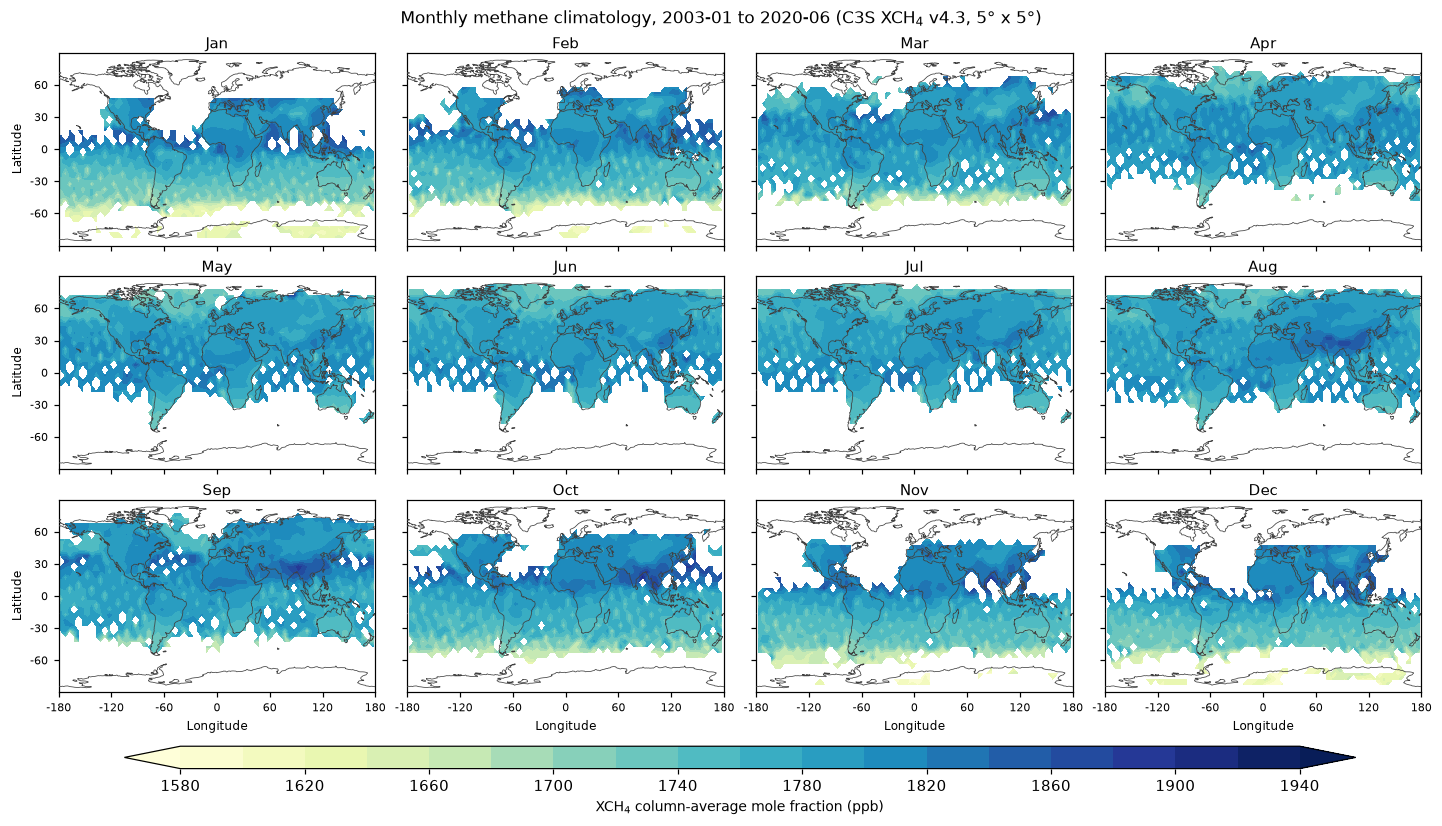

annual cycle of the global mean, from the 12 climatology panels:
    [1761.6 1768.1 1774.  1784.5 1787.3 1786.2 1783.7 1786.8 1783.7 1774.7
 1767.7 1765.9]
    amplitude: 25.71 ppb


In [7]:
# --- 1.1 plot the 12 climatology panels ----------------------------------
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
LEVELS = np.arange(1580, 1941, 20)

fig, axes = plt.subplots(3, 4, figsize=(13.0, 7.4),
                         sharex=True, sharey=True,
                         constrained_layout=True)
cf = None
for k, ax in enumerate(axes.ravel()):
    cf = ax.contourf(lon, lat, clim.isel(month=k), levels=LEVELS,
                     cmap="YlGnBu", extend="both")
    add_coast(ax)
    ax.set_title(MONTHS[k], fontsize=10, pad=3)
    ax.set_xticks([-180, -120, -60, 0, 60, 120, 180])
    ax.set_yticks([-60, -30, 0, 30, 60])
    ax.grid(False)
    ax.tick_params(labelsize=7)
for ax in axes[-1]:
    ax.set_xlabel("Longitude", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Latitude", fontsize=8)

cbar = fig.colorbar(cf, ax=axes, orientation="horizontal",
                    fraction=0.035, pad=0.02, aspect=55)
cbar.set_label("XCH$_4$ column-average mole fraction (ppb)", fontsize=9)
fig.suptitle("Monthly methane climatology, 2003-01 to 2020-06 "
             "(C3S XCH$_4$ v4.3, 5$\\degree$ x 5$\\degree$)", fontsize=11)
fig.savefig(os.path.join(FIG_DIR, "p1_1_monthly_climatology.png"))
plt.show()

print("annual cycle of the global mean, from the 12 climatology panels:")
gm_clim = np.array([float(clim.sel(month=m).weighted(weights).mean())
                    for m in range(1, 13)])
print("   ", np.round(gm_clim, 1))
print("    amplitude:", round(float(gm_clim.max() - gm_clim.min()), 2), "ppb")

In [8]:
# --- 1.2 globally averaged methane ---------------------------------------
# Area-weighted global mean of every monthly field.
global_mean = xch4_ppb.weighted(weights).mean(dim=("lat", "lon"))
print("series length:", global_mean.size)
print("first / last :", round(float(global_mean[0]), 2),
      round(float(global_mean[-1]), 2), "ppb")
print("months that are entirely missing:",
      [str(t)[:7] for t in time.values[np.isnan(global_mean.values)]])

annual = global_mean.groupby("time.year").mean()
print("\nyear   mean(ppb)   n_months")
for y, v in zip(annual.year.values, annual.values):
    n = int((time.dt.year.values == y).sum())
    print("%5d  %9.2f   %d" % (y, v, n))

series length: 210
first / last : 1713.49 1850.67 ppb
months that are entirely missing: ['2015-01']

year   mean(ppb)   n_months
 2003    1735.39   12
 2004    1735.21   12
 2005    1741.28   12
 2006    1748.41   12
 2007    1754.28   12
 2008    1765.17   12
 2009    1764.66   12
 2010    1769.92   12
 2011    1777.05   12
 2012    1783.69   12
 2013    1787.61   12
 2014    1795.11   12
 2015    1803.86   12
 2016    1811.80   12
 2017    1818.46   12
 2018    1829.12   12
 2019    1835.64   12
 2020    1843.67   6


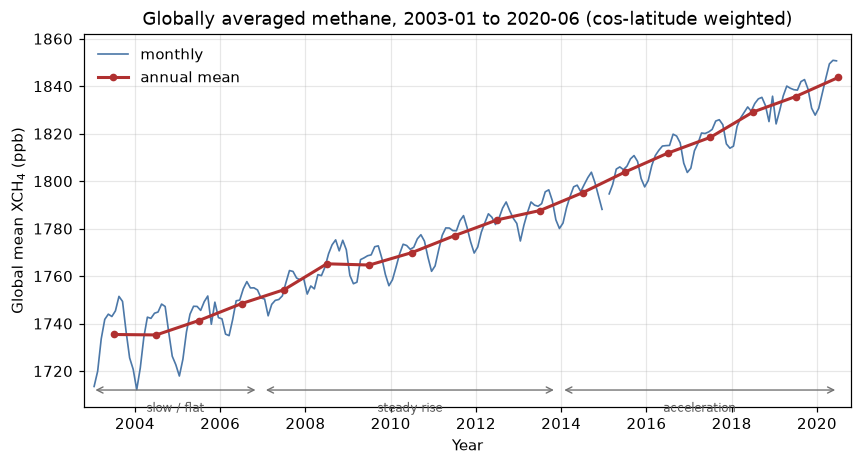

In [9]:
# --- 1.2 plot the global mean time series --------------------------------
tnum = time.dt.year + (time.dt.month - 0.5) / 12.0

fig, ax = plt.subplots(figsize=(9.0, 4.4))
ax.plot(tnum, global_mean, "-", color="#4c78a8", lw=1.1, label="monthly")
ax.plot(annual.year + 0.5, annual, "o-", color="#b03030", lw=2.0, ms=4,
        label="annual mean")
ax.set_xlabel("Year")
ax.set_ylabel("Global mean XCH$_4$ (ppb)")
ax.set_title("Globally averaged methane, 2003-01 to 2020-06 "
             "(cos-latitude weighted)")
ax.set_xlim(2002.8, 2020.8)
ax.set_ylim(1705, 1862)
ax.legend(loc="upper left", frameon=False)
ax.grid(True, alpha=0.3)

# annotate the three regimes that are visible in the curve
for x0, x1, txt in [(2003.0, 2006.9, "slow / flat"),
                    (2007.0, 2013.9, "steady rise"),
                    (2014.0, 2020.5, "acceleration")]:
    y = 1712
    ax.annotate("", xy=(x0, y), xytext=(x1, y),
                arrowprops=dict(arrowstyle="<->", color="0.45", lw=0.9))
    ax.text((x0 + x1) / 2, y - 5, txt, ha="center", va="top",
            fontsize=8, color="0.35")

fig.savefig(os.path.join(FIG_DIR, "p1_2_global_mean_timeseries.png"))
plt.show()

In [10]:
# --- 1.2 quantify the regimes --------------------------------------------
def seg_trend(y0, y1):
    """Least-squares slope of the global mean over [y0, y1], in ppb/decade."""
    m = (time.dt.year.values >= y0) & (time.dt.year.values <= y1)
    y = global_mean.values[m]
    x = np.arange(m.sum(), dtype=float)
    ok = ~np.isnan(y)
    slope = np.polyfit(x[ok], y[ok], 1)[0]
    return slope * 120.0


print("segment trends of the global mean (ppb/decade):")
for y0, y1, name in [(2003, 2006, "2003-2006"),
                     (2007, 2013, "2007-2013"),
                     (2014, 2020, "2014-2020"),
                     (2003, 2020, "2003-2020")]:
    print("   %-9s : %+6.2f" % (name, seg_trend(y0, y1)))

rise = float(annual.sel(year=2019) - annual.sel(year=2003))
print("\n2003 -> 2019 annual-mean change: %+.1f ppb" % rise)

segment trends of the global mean (ppb/decade):
   2003-2006 : +51.98
   2007-2013 : +54.48
   2014-2020 : +82.84
   2003-2020 : +64.35

2003 -> 2019 annual-mean change: +100.2 ppb


In [11]:
# --- 1.3 deseasonalised methane at 15S, 150W -----------------------------
# The requested point falls between four 5-degree cells, so the nearest cell is
# a poor representative and its retrieval coverage is patchy.  A 3x3 box
# centred on the point keeps the local signal while roughly doubling the number
# of months that actually have data.
TARGET_LAT, TARGET_LON = -15.0, -150.0
j = int(np.argmin(np.abs(lat.values - TARGET_LAT)))
k = int(np.argmin(np.abs(lon.values - TARGET_LON)))
print("nearest cell :", float(lat[j]), float(lon[k]))
print("box          : lat %.1f..%.1f, lon %.1f..%.1f"
      % (lat[j - 1], lat[j + 1], lon[k - 1], lon[k + 1]))

point_raw = xch4_ppb.isel(lat=[j], lon=[k]).squeeze("lat").squeeze("lon")
box_raw = xch4_ppb.isel(lat=slice(j - 1, j + 2),
                        lon=slice(k - 1, k + 2)).mean(dim=("lat", "lon"),
                                                       skipna=True)
print("valid months, single cell:", int((~np.isnan(point_raw)).sum()), "/", time.size)
print("valid months, 3x3 box    :", int((~np.isnan(box_raw)).sum()), "/", time.size)

series = box_raw.values.astype(float)
t = np.arange(series.size, dtype=float)
month = time.dt.month.values
ok = ~np.isnan(series)

nearest cell : -17.5 -152.5
box          : lat -22.5..-12.5, lon -157.5..-147.5
valid months, single cell: 88 / 210
valid months, 3x3 box    : 114 / 210


In [12]:
# --- 1.3 remove the seasonal cycle with a harmonic fit -------------------
# Two harmonics (annual + semi-annual) plus a linear trend are fitted by least
# squares, and only the harmonic part is subtracted.  The trend is kept in the
# series so that the long-term rise stays visible.
ang = 2.0 * np.pi * (month - 1) / 12.0


def design(tt, mm):
    return np.column_stack([
        np.ones(tt.size), tt,
        np.cos(ang[mm - 1]), np.sin(ang[mm - 1]),
        np.cos(2 * ang[mm - 1]), np.sin(2 * ang[mm - 1]),
    ])


A = design(t[ok], month[ok])
coef, *_ = np.linalg.lstsq(A, series[ok], rcond=None)
fitted = design(t, month) @ coef

# the pure seasonal part: the same design with intercept and trend switched off
seasonal = design(t, month) @ np.array([0.0, 0.0,
                                        coef[2], coef[3], coef[4], coef[5]])
deseason = series - seasonal          # level and trend are kept on purpose

print("fitted coefficients: intercept %.2f, trend %.3f ppb/month"
      % (coef[0], coef[1]))
print("trend             : %+.2f ppb/decade" % (coef[1] * 120))
print("seasonal amplitude: %.2f ppb" % (np.nanmax(seasonal) - np.nanmin(seasonal)))
print("deseasonalised std: %.2f ppb" % np.nanstd(deseason))
print("deseasonalised rng: %.1f .. %.1f ppb"
      % (np.nanmin(deseason), np.nanmax(deseason)))

fitted coefficients: intercept 1690.73, trend 0.606 ppb/month
trend             : +72.72 ppb/decade
seasonal amplitude: 15.62 ppb
deseasonalised std: 34.66 ppb
deseasonalised rng: 1686.1 .. 1821.7 ppb


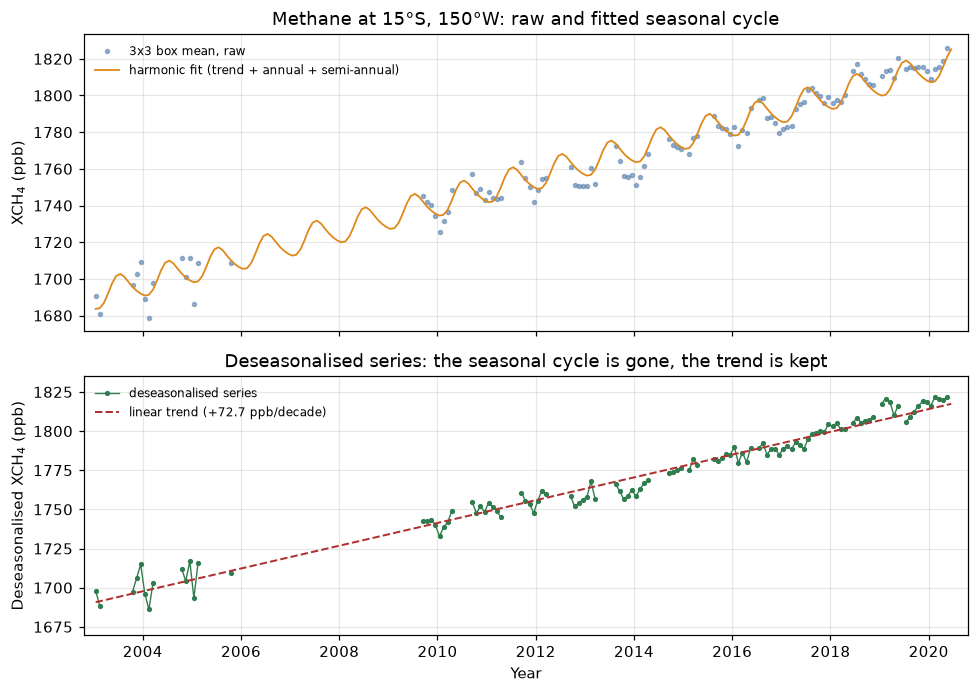

change of the deseasonalised series, first vs last decade of valid data:
   first 12 valid months: 1701.3 ppb
   last  12 valid months: 1816.4 ppb
   difference           : +115.1 ppb


In [13]:
# --- 1.3 plot the deseasonalised series ----------------------------------
fig, axes = plt.subplots(2, 1, figsize=(9.0, 6.4), sharex=True,
                         gridspec_kw={"height_ratios": [1.15, 1.0]})

ax = axes[0]
ax.plot(tnum, series, "o", ms=2.6, color="#4c78a8", alpha=0.55,
        label="3x3 box mean, raw")
ax.plot(tnum, fitted, "-", color="#e08a1e", lw=1.2,
        label="harmonic fit (trend + annual + semi-annual)")
ax.set_ylabel("XCH$_4$ (ppb)")
ax.set_title("Methane at 15$\\degree$S, 150$\\degree$W: raw and fitted seasonal cycle")
ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(tnum, deseason, "o-", ms=2.4, lw=0.9, color="#2f7d4f",
        label="deseasonalised series")
ax.plot(tnum, coef[0] + coef[1] * t, "--", color="#b03030", lw=1.3,
        label="linear trend (%+.1f ppb/decade)" % (coef[1] * 120))
ax.set_xlabel("Year")
ax.set_ylabel("Deseasonalised XCH$_4$ (ppb)")
ax.set_title("Deseasonalised series: the seasonal cycle is gone, the trend is kept")
ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.grid(True, alpha=0.3)
ax.set_xlim(2002.8, 2020.8)
ax.set_ylim(1670, 1835)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "p1_3_deseasonalised_point.png"))
plt.show()

print("change of the deseasonalised series, first vs last decade of valid data:")
ok_idx = np.where(ok)[0]
early = np.nanmean(deseason[ok_idx[:12]])
late = np.nanmean(deseason[ok_idx[-12:]])
print("   first 12 valid months: %.1f ppb" % early)
print("   last  12 valid months: %.1f ppb" % late)
print("   difference           : %+.1f ppb" % (late - early))

In [14]:
# --- 2.0 environment ------------------------------------------------------
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.unicode_minus": False,
})

In [15]:
# --- 2.0 open the file ----------------------------------------------------
SST_FILE = os.path.join(DATA_DIR, "NOAA_NCDC_ERSST_v3b_SST.nc")
ds_sst = xr.open_dataset(SST_FILE, decode_times=True)
print(ds_sst)

sst = ds_sst["sst"]
print("\nsst shape :", sst.shape, " dtype:", sst.dtype)
print("time span :", str(sst.time.values[0])[:10], "->", str(sst.time.values[-1])[:10],
      " n =", sst.time.size)
print("lat       :", float(sst.lat[0]), "..", float(sst.lat[-1]),
      " n =", sst.lat.size)
print("lon       :", float(sst.lon[0]), "..", float(sst.lon[-1]),
      " n =", sst.lon.size, "(0-360 convention)")
print("missing   :", int(np.isnan(sst.values).sum()), "of", sst.size,
      "(land and ice)")

<xarray.Dataset> Size: 44MB
Dimensions:  (time: 684, lat: 89, lon: 180)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1960-01-15 1960-02-15 ... 2016-12-15
  * lat      (lat) float32 356B -88.0 -86.0 -84.0 -82.0 ... 82.0 84.0 86.0 88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Data variables:
    sst      (time, lat, lon) float32 44MB ...
Attributes:
    Conventions:  IRIDL
    source:       https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/...
    history:      extracted and cleaned by Ryan Abernathey for Research Compu...

sst shape : (684, 89, 180)  dtype: float32
time span : 1960-01-15 -> 2016-12-15  n = 684
lat       : -88.0 .. 88.0  n = 89
lon       : 0.0 .. 358.0  n = 180 (0-360 convention)


missing   : 3441888 of 10957680 (land and ice)


In [16]:
# --- 2.0 pick the Nino 3.4 box -------------------------------------------
# 5N-5S, 170W-120W.  The file stores longitude as 0..360, so the two bounds
# become 190E and 240E; using -170/-120 directly would select an empty range.
LAT_S, LAT_N = -5.0, 5.0
LON_W, LON_E = 190.0, 240.0

nino34 = sst.sel(lat=slice(LAT_S, LAT_N), lon=slice(LON_W, LON_E))
print("box shape:", nino34.shape, " lat:", nino34.lat.values,
      " lon:", nino34.lon.values)

# quick check that the box really is the central-eastern equatorial Pacific
print("mean SST in the box over the whole record: %.2f degC"
      % float(nino34.mean()))

box shape: (684, 5, 26)  lat: [-4. -2.  0.  2.  4.]  lon: [190. 192. 194. 196. 198. 200. 202. 204. 206. 208. 210. 212. 214. 216.
 218. 220. 222. 224. 226. 228. 230. 232. 234. 236. 238. 240.]
mean SST in the box over the whole record: 27.04 degC


In [17]:
# --- 2.0 area-weighted regional mean -------------------------------------
# Same argument as for the methane grid: a 2-degree cell near 5N is smaller
# than one at the equator, so weight by cos(lat).
w34 = np.cos(np.deg2rad(nino34.lat))
n34 = nino34.weighted(w34).mean(dim=("lat", "lon"))
print("regional mean series:", n34.size, "months")
print("first / last       :", round(float(n34[0]), 2), round(float(n34[-1]), 2))
print("missing values     :", int(np.isnan(n34.values).sum()))

regional mean series: 684 months
first / last       : 26.25 25.76
missing values     : 0


In [18]:
# --- 2.1 monthly climatology ---------------------------------------------
# A fixed 30-year base period (1981-2010) is used so that the anomalies stay
# comparable through time; a climatology computed over the whole record would
# absorb part of the long-term warming and damp the recent anomalies.
BASE_Y0, BASE_Y1 = 1981, 2010
base = (n34.time.dt.year >= BASE_Y0) & (n34.time.dt.year <= BASE_Y1)
print("base period months:", int(base.sum()))

clim = n34.where(base, drop=True).groupby("time.month").mean("time")
print("\nNino 3.4 monthly climatology (1981-2010):")
for m in range(1, 13):
    print("   month %2d : %6.3f degC" % (m, float(clim.sel(month=m))))
print("annual range: %.2f degC"
      % float(clim.max() - clim.min()))

base period months: 360

Nino 3.4 monthly climatology (1981-2010):
   month  1 : 26.671 degC
   month  2 : 26.841 degC
   month  3 : 27.339 degC
   month  4 : 27.805 degC
   month  5 : 27.913 degC
   month  6 : 27.689 degC
   month  7 : 27.275 degC
   month  8 : 26.924 degC
   month  9 : 26.829 degC
   month 10 : 26.790 degC
   month 11 : 26.737 degC
   month 12 : 26.691 degC
annual range: 1.24 degC


In [19]:
# --- 2.1 anomalies --------------------------------------------------------
month = n34.time.dt.month
clim_full = clim.sel(month=month).values
n34_anom = xr.DataArray(n34.values - clim_full,
                        dims="time", coords={"time": n34.time},
                        name="n34_anom",
                        attrs={"units": "degC",
                               "long_name": "Nino 3.4 SST anomaly"})

print("anomaly std : %.3f degC" % float(n34_anom.std()))
print("anomaly min : %.2f degC" % float(n34_anom.min()))
print("anomaly max : %.2f degC" % float(n34_anom.max()))
print("\nfirst 12 months:")
print(np.round(n34_anom.values[:12], 2))

anomaly std : 0.858 degC
anomaly min : -2.26 degC
anomaly max : 2.66 degC

first 12 months:
[-0.42 -0.57 -0.37 -0.3  -0.3  -0.45 -0.22 -0.08 -0.24 -0.45 -0.4  -0.29]


In [20]:
# --- 2.2 three-month running mean ----------------------------------------
# The index is defined on a 3-month running mean, which removes the
# month-to-month noise and is the quantity used by the +/-0.5 degC rule.
n34_3m = n34_anom.rolling(time=3, center=True).mean()
print("3-month running mean: first/last are NaN by construction:",
      bool(np.isnan(n34_3m.values[0])), bool(np.isnan(n34_3m.values[-1])))
print("3m std : %.3f degC" % float(n34_3m.std()))
print("3m min : %.2f degC" % float(n34_3m.min()))
print("3m max : %.2f degC" % float(n34_3m.max()))

3-month running mean: first/last are NaN by construction: True True
3m std : 0.837 degC
3m min : -2.22 degC
3m max : 2.49 degC


In [21]:
# --- 2.2 detect El Nino and La Nina events -------------------------------
# Rule from the assignment: |3-month mean| >= 0.5 degC for at least 5 months.
THRESH = 0.5
MIN_LEN = 5


def find_events(series, sign):
    """Return (start, end, n_months, peak) for every run above the threshold."""
    flag = (series * sign >= THRESH)
    out, i, n = [], 0, series.size
    while i < n:
        if bool(flag[i]) and not np.isnan(series[i]):
            j = i
            while j < n and bool(flag[j]) and not np.isnan(series[j]):
                j += 1
            if j - i >= MIN_LEN:
                peak = float(np.nanmax(series[i:j] * sign))
                out.append((i, j - 1, j - i, peak))
            i = j
        else:
            i += 1
    return out


def label(i):
    return str(n34_3m.time.values[i])[:7]


events = {}
for sign, name in ((+1, "El Nino"), (-1, "La Nina")):
    ev = find_events(n34_3m.values, sign)
    events[name] = ev
    print("\n%s events (>= %.1f degC for >= %d months): %d"
          % (name, THRESH, MIN_LEN, len(ev)))
    print("   start     end       months  peak(degC)")
    for a, b, ln, pk in ev:
        # peak is a magnitude; restore the sign so the table reads correctly
        print("   %-9s %-9s %4d    %+5.2f" % (label(a), label(b), ln, pk * sign))


El Nino events (>= 0.5 degC for >= 5 months): 14
   start     end       months  peak(degC)
   1963-08   1964-01      6    +0.88
   1965-07   1966-03      9    +1.45
   1968-11   1969-04      6    +0.91
   1972-06   1973-02      9    +1.94
   1982-06   1983-05     12    +2.16
   1986-09   1988-01     17    +1.47
   1991-06   1992-06     13    +1.62
   1994-09   1995-03      7    +1.20
   1997-05   1998-04     12    +2.36
   2002-05   2003-02     10    +1.31
   2004-07   2005-01      7    +0.75
   2006-09   2007-01      5    +1.00
   2009-07   2010-04     10    +1.63
   2015-03   2016-04     14    +2.49

La Nina events (>= 0.5 degC for >= 5 months): 16
   start     end       months  peak(degC)
   1961-08   1962-06     11    -0.76
   1962-08   1963-01      6    -0.87
   1964-04   1965-02     11    -1.31
   1967-09   1968-04      8    -0.97
   1970-07   1972-01     19    -1.41
   1973-05   1976-05     37    -2.22
   1978-05   1978-09      5    -0.60
   1983-09   1984-01      5    -1.03
  

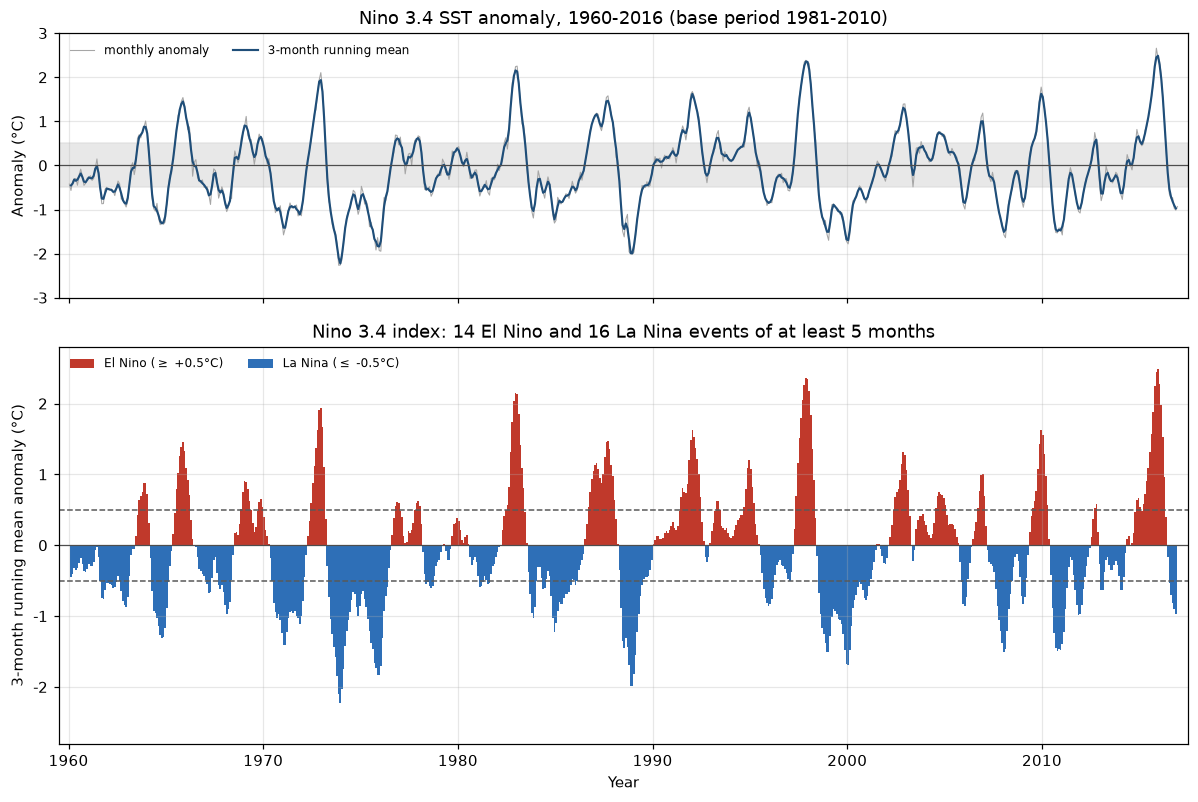

In [22]:
# --- 2.2 plot the index --------------------------------------------------
# Layout follows the NCDC reference figure: a bar per month, red when the
# 3-month mean is at or above +0.5 degC, blue when at or below -0.5 degC.  The
# thin line above the bars is the unsmoothed monthly anomaly, which shows how
# much of the month-to-month noise the running mean removes.
tn = n34_3m.time.dt.year + (n34_3m.time.dt.month - 0.5) / 12.0
vals = n34_3m.values
anom_monthly = n34_anom.values

fig, axes = plt.subplots(2, 1, figsize=(11.0, 7.4), sharex=True,
                         gridspec_kw={"height_ratios": [1.0, 1.5]})

# --- upper panel: monthly anomaly and its 3-month running mean
ax = axes[0]
ax.plot(tn, anom_monthly, "-", color="0.65", lw=0.7, label="monthly anomaly")
ax.plot(tn, vals, "-", color="#1f4e79", lw=1.4, label="3-month running mean")
ax.axhline(0, color="0.3", lw=0.8)
ax.axhspan(-THRESH, THRESH, color="0.85", alpha=0.6, zorder=0)
ax.set_ylim(-3.0, 3.0)
ax.set_ylabel("Anomaly ($\\degree$C)")
ax.set_title("Nino 3.4 SST anomaly, 1960-2016 (base period 1981-2010)")
ax.legend(loc="upper left", frameon=False, fontsize=8, ncol=2)
ax.grid(True, alpha=0.3, axis="y")

# --- lower panel: the index as bars
ax = axes[1]
pos = vals >= 0
ax.bar(tn[pos], vals[pos], width=0.085, color="#c0392b",
       label="El Nino ($\\geq$ +0.5$\\degree$C)")
ax.bar(tn[~pos], vals[~pos], width=0.085, color="#2e6fb7",
       label="La Nina ($\\leq$ -0.5$\\degree$C)")
ax.axhline(0, color="0.3", lw=0.8)
for y in (THRESH, -THRESH):
    ax.axhline(y, color="0.35", lw=1.0, ls="--")
ax.set_ylim(-2.8, 2.8)
ax.set_xlim(1959.5, 2017.5)
ax.set_xlabel("Year")
ax.set_ylabel("3-month running mean anomaly ($\\degree$C)")
ax.set_title("Nino 3.4 index: 14 El Nino and 16 La Nina events of at least 5 months")
ax.legend(loc="upper left", frameon=False, fontsize=8, ncol=2)
ax.grid(True, alpha=0.3, axis="y")

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "p2_2_nino34_index.png"))
plt.show()

In [23]:
# --- 2.2 strongest events -------------------------------------------------
# peak is stored as a magnitude (the search multiplies by the sign), so it has
# to be given the sign back when it is printed.
strong = sorted(events["El Nino"], key=lambda e: -e[3])[:5]
print("five strongest El Nino events by peak 3-month anomaly:")
for a, b, ln, pk in strong:
    print("   %s .. %s  (%2d months)  peak %+.2f degC"
          % (label(a), label(b), ln, pk))

strong_l = sorted(events["La Nina"], key=lambda e: -e[3])[:5]
print("\nfive strongest La Nina events by peak 3-month anomaly:")
for a, b, ln, pk in strong_l:
    print("   %s .. %s  (%2d months)  peak %+.2f degC"
          % (label(a), label(b), ln, -pk))

five strongest El Nino events by peak 3-month anomaly:
   2015-03 .. 2016-04  (14 months)  peak +2.49 degC
   1997-05 .. 1998-04  (12 months)  peak +2.36 degC
   1982-06 .. 1983-05  (12 months)  peak +2.16 degC
   1972-06 .. 1973-02  ( 9 months)  peak +1.94 degC
   2009-07 .. 2010-04  (10 months)  peak +1.63 degC

five strongest La Nina events by peak 3-month anomaly:
   1973-05 .. 1976-05  (37 months)  peak -2.22 degC
   1988-05 .. 1989-06  (14 months)  peak -1.99 degC
   1998-07 .. 2001-02  (32 months)  peak -1.70 degC
   2007-08 .. 2008-06  (11 months)  peak -1.51 degC
   2010-07 .. 2011-04  (10 months)  peak -1.49 degC


In [24]:
# --- 2.2 fraction of time spent in each state ----------------------------
v = n34_3m.values
ok = ~np.isnan(v)
print("share of months with |anomaly| >= 0.5 degC: %.1f %%"
      % (100.0 * np.sum(np.abs(v[ok]) >= THRESH) / ok.sum()))
print("   El Nino side: %.1f %%" % (100.0 * np.sum(v[ok] >= THRESH) / ok.sum()))
print("   La Nina side: %.1f %%" % (100.0 * np.sum(v[ok] <= -THRESH) / ok.sum()))
print("share of months that belong to a >=5-month event: %.1f %%"
      % (100.0 * sum(e[2] for e in events["El Nino"] + events["La Nina"]) / ok.sum()))

share of months with |anomaly| >= 0.5 degC: 55.3 %
   El Nino side: 22.4 %
   La Nina side: 32.8 %
share of months that belong to a >=5-month event: 49.4 %


In [25]:
# --- 3.0 environment ------------------------------------------------------
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.unicode_minus": False,
})

In [26]:
# --- 3.0 the dataset ------------------------------------------------------
# CESM2 historical (CMIP6) monthly near-surface air temperature, member
# r11i1p1f1, Jan 2000 - Dec 2014.  A model run is used instead of a satellite
# product because it is a single self-consistent, gap-free, globally complete
# field: no missing months, no retrieval holes, which keeps the exploration
# focused on the analysis rather than on quality control.
TAS_FILE = os.path.join(DATA_DIR, "CESM2_200001-201412_tas.nc")
ds_tas = xr.open_dataset(TAS_FILE, decode_times=True)
print(ds_tas)

print("\n--- provenance ---")
for k in ("source_id", "experiment_id", "variant_label", "table_id",
          "variable_id", "nominal_resolution", "institution_id"):
    print("  %-18s: %s" % (k, ds_tas.attrs.get(k)))

<xarray.Dataset> Size: 40MB
Dimensions:    (time: 180, lat: 192, lon: 288, nbnd: 2)
Coordinates:
  * time       (time) object 1kB 2000-01-15 12:00:00 ... 2014-12-15 12:00:00
  * lat        (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * lon        (lon) float64 2kB 0.0 1.25 2.5 3.75 ... 355.0 356.2 357.5 358.8
Dimensions without coordinates: nbnd
Data variables:
    tas        (time, lat, lon) float32 40MB ...
    time_bnds  (time, nbnd) object 3kB ...
    lat_bnds   (lat, nbnd) float64 3kB ...
    lon_bnds   (lon, nbnd) float64 5kB ...
Attributes: (12/45)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   674885.0
    branch_time_in_parent:  219000.0
    case_id:                972
    ...                     ...
    sub_experiment_id:      none
    table_id:               Amon
    tracking_id:            hdl:21.14100/a7278f6d-6a1b-4050-8f06-a8033604736a
    variable_id:   

G:\Anaconda3\Lib\site-packages\xarray\conventions.py:205: SerializationWarning: variable 'tas' has multiple fill values {np.float32(1e+20), np.float64(1e+20)} defined, decoding all values to NaN.
  var = coder.decode(var, name=name)


In [27]:
# --- 3.0 decode and basic checks -----------------------------------------
tas = ds_tas["tas"]
print("shape     :", tas.shape, " dtype:", tas.dtype)
print("units     :", tas.attrs.get("units"))
print("time span :", str(tas.time.values[0])[:10], "->", str(tas.time.values[-1])[:10],
      " n =", tas.time.size)
print("calendar  :", ds_tas["time"].attrs.get("calendar"))
print("lat range :", float(tas.lat[0]), "..", float(tas.lat[-1]),
      " n =", tas.lat.size)
print("lon range :", float(tas.lon[0]), "..", float(tas.lon[-1]),
      " n =", tas.lon.size)
print("missing   :", int(np.isnan(tas.values).sum()))

# The file carries two conflicting fill values (1e20 as float32 and float64),
# so xarray decodes the field to NaN instead of masking it.  Here nothing is
# missing, but the conversion to degC is still needed: the field is in kelvin.
tas_c = tas - 273.15
tas_c.attrs["units"] = "degC"
tas_c.attrs["long_name"] = "Near-surface air temperature"
print("\nafter conversion to degC: %.2f .. %.2f  (mean %.2f)"
      % (float(tas_c.min()), float(tas_c.max()), float(tas_c.mean())))

shape     : (180, 192, 288)  dtype: float32
units     : K
time span : 2000-01-15 -> 2014-12-15  n = 180
calendar  : None
lat range : -90.0 .. 90.0  n = 192
lon range : 0.0 .. 358.75  n = 288


missing   : 0

after conversion to degC: -66.26 .. 43.35  (mean 5.61)


In [28]:
# --- 3.0 area weights -----------------------------------------------------
# Gaussian grid: the rows are equally spaced in latitude, so cos(lat) is again
# the correct area factor.
w = np.cos(np.deg2rad(tas_c.lat))
print("lat spacing: first %.3f, middle %.3f"
      % (float(tas_c.lat[1] - tas_c.lat[0]),
         float(tas_c.lat[96] - tas_c.lat[95])))

lat spacing: first 0.942, middle 0.942


In [29]:
# --- 3.1 global mean and its seasonal cycle ------------------------------
gm = tas_c.weighted(w).mean(dim=("lat", "lon"))
print("global mean series:", gm.size, "months")
print("first / last      : %.2f / %.2f degC"
      % (float(gm[0]), float(gm[-1])))
print("range             : %.2f .. %.2f degC"
      % (float(gm.min()), float(gm.max())))

# monthly climatology over the 15 available years
clim = gm.groupby("time.month").mean("time")
print("\nglobal-mean annual cycle:")
for m in range(1, 13):
    print("   month %2d : %6.2f degC" % (m, float(clim.sel(month=m))))
print("amplitude: %.2f degC" % float(clim.max() - clim.min()))

global mean series: 180 months
first / last      : 12.60 / 13.91 degC
range             : 12.60 .. 16.89 degC



global-mean annual cycle:
   month  1 :  13.11 degC
   month  2 :  13.23 degC
   month  3 :  13.86 degC
   month  4 :  14.81 degC
   month  5 :  15.66 degC
   month  6 :  16.30 degC
   month  7 :  16.59 degC
   month  8 :  16.45 degC
   month  9 :  15.82 degC
   month 10 :  15.01 degC
   month 11 :  14.16 degC
   month 12 :  13.47 degC
amplitude: 3.49 degC


In [30]:
# --- 3.1 remove the seasonal cycle ---------------------------------------
month = gm.time.dt.month
gm_deseason = gm - clim.sel(month=month)
gm_deseason.name = "tas_deseason"

print("deseasonalised std: %.3f K" % float(gm_deseason.std()))
print("deseasonalised min/max: %.2f .. %.2f K"
      % (float(gm_deseason.min()), float(gm_deseason.max())))

# linear trend of the deseasonalised series
tnum = gm_deseason.time.dt.year + (gm_deseason.time.dt.month - 0.5) / 12.0
coef = np.polyfit(tnum.values, gm_deseason.values, 1)
print("\nlinear trend: %+.3f K/decade" % (coef[0] * 10))
print("              %+.3f K over the 15 years" % (coef[0] * 15))
print("fit at 2000.0: %.2f K" % np.polyval(coef, 2000.0))

deseasonalised std: 0.195 K
deseasonalised min/max: -0.50 .. 0.65 K

linear trend: +0.315 K/decade
              +0.473 K over the 15 years
fit at 2000.0: -0.24 K


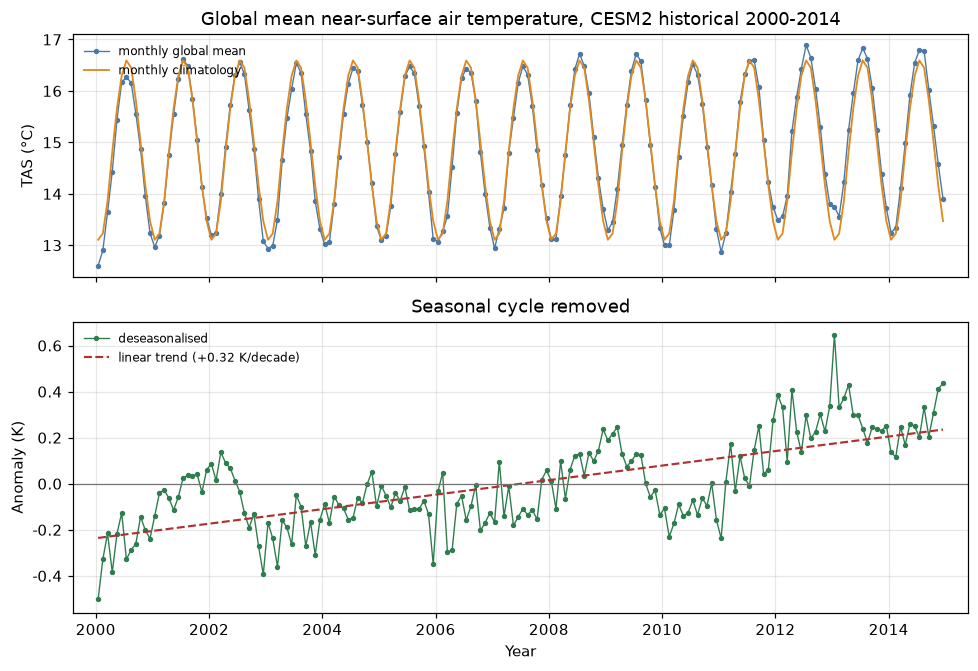

In [31]:
# --- 3.1 plot the deseasonalised series ----------------------------------
fig, axes = plt.subplots(2, 1, figsize=(9.0, 6.2), sharex=True,
                         gridspec_kw={"height_ratios": [1.0, 1.2]})

ax = axes[0]
ax.plot(tnum, gm, "-o", ms=2.5, lw=0.9, color="#4c78a8", label="monthly global mean")
ax.plot(tnum, clim.sel(month=month), "-", lw=1.2, color="#e08a1e",
        label="monthly climatology")
ax.set_ylabel("TAS ($\\degree$C)")
ax.set_title("Global mean near-surface air temperature, CESM2 historical 2000-2014")
ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(tnum, gm_deseason, "-o", ms=2.5, lw=0.9, color="#2f7d4f",
        label="deseasonalised")
ax.plot(tnum, np.polyval(coef, tnum), "--", color="#b03030", lw=1.4,
        label="linear trend (%+.2f K/decade)" % (coef[0] * 10))
ax.axhline(0, color="0.45", lw=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("Anomaly (K)")
ax.set_title("Seasonal cycle removed")
ax.legend(loc="upper left", frameon=False, fontsize=8)
ax.grid(True, alpha=0.3)
ax.set_xlim(1999.6, 2015.4)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "p3_1_deseasonalised_timeseries.png"))
plt.show()

time-mean field: -51.9 .. 32.2 degC
warmest grid cell at lat 13.7, lon 41.2


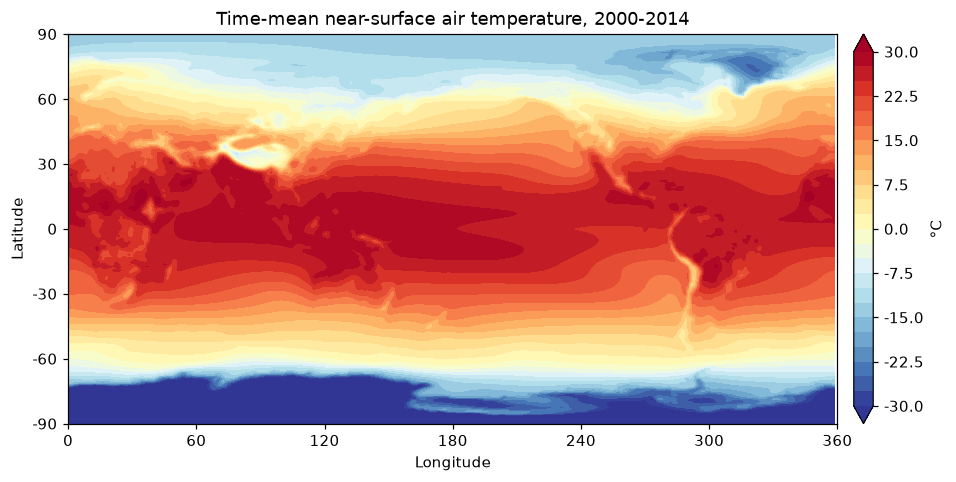

In [32]:
# --- 3.2 plot 1: the time-mean field -------------------------------------
mean_field = tas_c.mean("time")
print("time-mean field: %.1f .. %.1f degC"
      % (float(mean_field.min()), float(mean_field.max())))
print("warmest grid cell at lat %.1f, lon %.1f"
      % (float(mean_field.lat.values[np.unravel_index(np.argmax(mean_field.values), mean_field.shape)[0]]),
         float(mean_field.lon.values[np.unravel_index(np.argmax(mean_field.values), mean_field.shape)[1]])))

fig, ax = plt.subplots(figsize=(9.6, 4.6))
cf = ax.contourf(tas_c.lon, tas_c.lat, mean_field, levels=np.arange(-30, 31, 2.5),
                 cmap="RdYlBu_r", extend="both")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Time-mean near-surface air temperature, 2000-2014")
ax.grid(False)
ax.set_xticks([0, 60, 120, 180, 240, 300, 360])
ax.set_yticks([-90, -60, -30, 0, 30, 60, 90])
cb = fig.colorbar(cf, ax=ax, pad=0.02, fraction=0.04)
cb.set_label("$\\degree$C")
fig.savefig(os.path.join(FIG_DIR, "p3_2a_mean_field.png"))
plt.show()

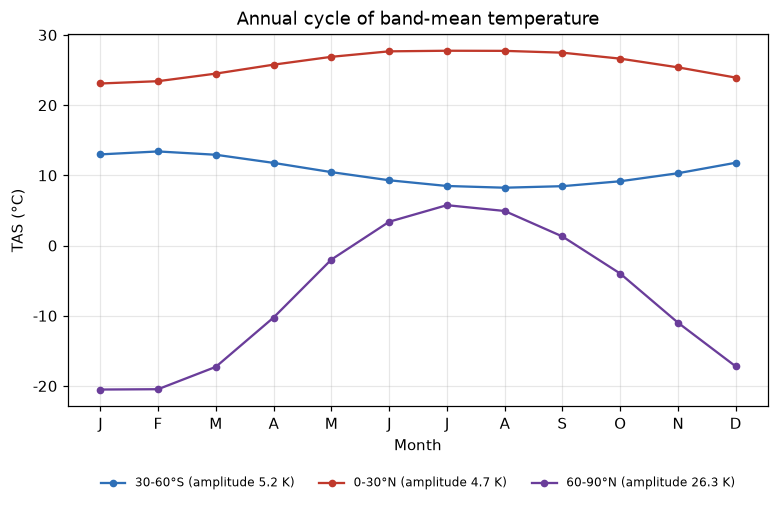

In [33]:
# --- 3.2 plot 2: the annual cycle at three latitudes ---------------------
# Same calendar month, three very different climates: the tropics barely have a
# seasonal cycle, the mid-latitudes have a large one, and the Arctic has the
# largest amplitude of all.
BANDS = [(-60, -30, "30-60$\\degree$S", "#2e6fb7"),
         (0, 30, "0-30$\\degree$N", "#c0392b"),
         (60, 90, "60-90$\\degree$N", "#6a3d9a")]

fig, ax = plt.subplots(figsize=(8.2, 4.4))
for s, n, lab, col in BANDS:
    band = tas_c.sel(lat=slice(s, n))
    wb = np.cos(np.deg2rad(band.lat))
    s_band = band.weighted(wb).mean(dim=("lat", "lon"))
    c_band = s_band.groupby("time.month").mean("time")
    ax.plot(np.arange(1, 13), c_band.values, "-o", ms=4, color=col,
            label="%s (amplitude %.1f K)"
            % (lab, float(c_band.max() - c_band.min())))
ax.set_xticks(np.arange(1, 13))
ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_xlabel("Month")
ax.set_ylabel("TAS ($\\degree$C)")
ax.set_title("Annual cycle of band-mean temperature")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), frameon=False,
          fontsize=8, ncol=3)
ax.grid(True, alpha=0.3)
fig.savefig(os.path.join(FIG_DIR, "p3_2b_annual_cycle_bands.png"))
plt.show()

zonal mean at the equator: 26.7 degC, at 80N: -13.3 degC


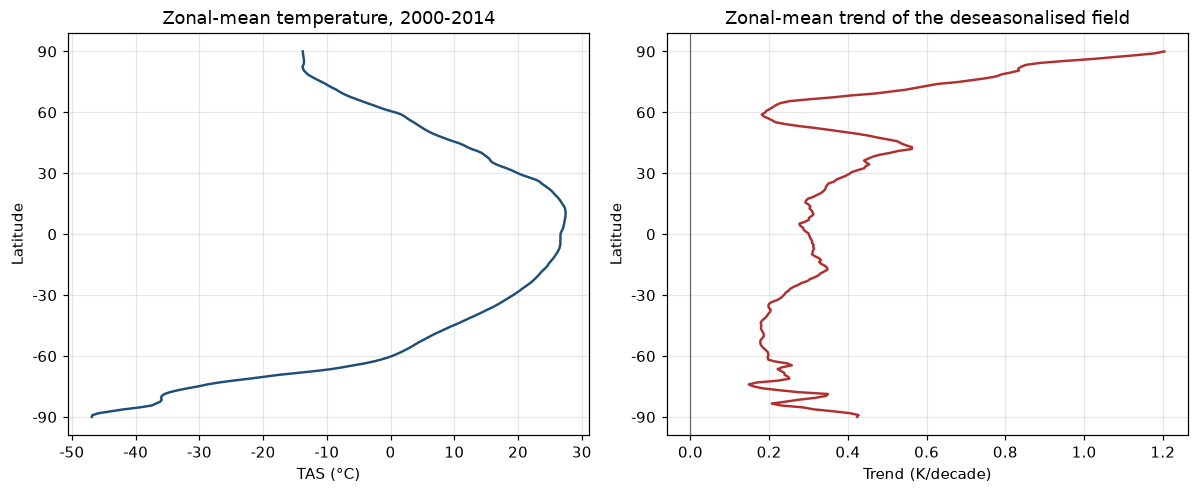


zonal-mean trend at selected latitudes (K/decade):
    -80 : +0.344
    -60 : +0.197
    -30 : +0.239
      0 : +0.300
     30 : +0.403
     60 : +0.189
     80 : +0.814


In [34]:
# --- 3.2 plot 3: zonal mean temperature and its trend --------------------
zonal = tas_c.mean("lon")
zonal_clim = zonal.mean("time")
print("zonal mean at the equator: %.1f degC, at 80N: %.1f degC"
      % (float(zonal_clim.sel(lat=0, method="nearest")),
         float(zonal_clim.sel(lat=80, method="nearest"))))

# xarray's polyfit on a datetime axis returns the slope per nanosecond, which
# is impossible to read.  Replacing the time coordinate by a plain month index
# makes the coefficient "per month" and the unit conversion explicit.
nmon = tas_c.sizes["time"]
month_index = np.arange(nmon, dtype=float)
anom = (tas_c.groupby("time.month") - tas_c.groupby("time.month").mean("time"))
anom = anom.assign_coords(time=month_index)

# per-latitude trend of the deseasonalised zonal mean
zonal_anom = anom.mean("lon")
zonal_trend = zonal_anom.polyfit("time", 1, skipna=True).polyfit_coefficients.sel(degree=1)

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.6))
ax = axes[0]
ax.plot(zonal_clim, zonal_clim.lat, "-", color="#1f4e79", lw=1.6)
ax.set_ylabel("Latitude")
ax.set_xlabel("TAS ($\\degree$C)")
ax.set_title("Zonal-mean temperature, 2000-2014")
ax.set_yticks([-90, -60, -30, 0, 30, 60, 90])
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(zonal_trend * 120, zonal_trend.lat, "-", color="#b03030", lw=1.6)
ax.axvline(0, color="0.4", lw=0.8)
ax.set_ylabel("Latitude")
ax.set_xlabel("Trend (K/decade)")
ax.set_title("Zonal-mean trend of the deseasonalised field")
ax.set_yticks([-90, -60, -30, 0, 30, 60, 90])
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "p3_2c_zonal_profile.png"))
plt.show()

print("\nzonal-mean trend at selected latitudes (K/decade):")
for la in (-80, -60, -30, 0, 30, 60, 80):
    print("   %4d : %+.3f" % (la, float(zonal_trend.sel(lat=la, method="nearest")) * 120))

grid-cell trend: -1.13 .. 2.20 K/decade (median 0.31)
area-weighted global trend: +0.32 K/decade


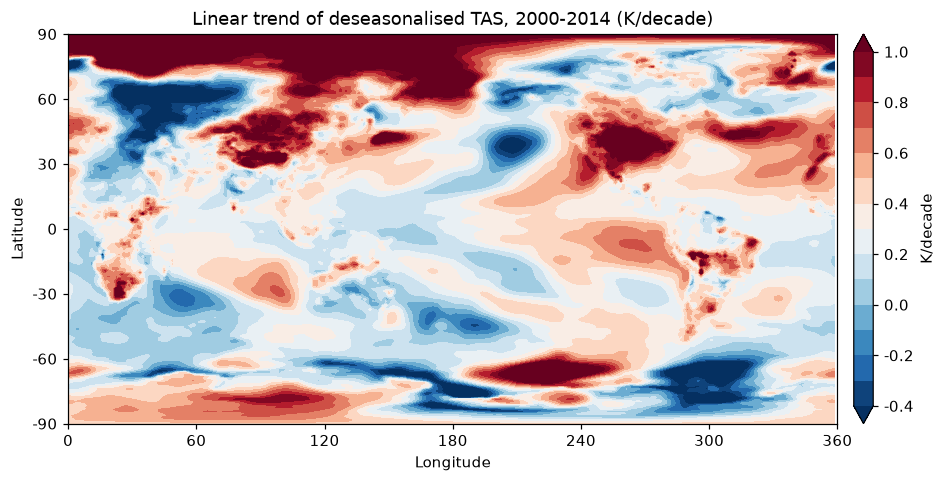

In [35]:
# --- 3.2 plot 4: the warming pattern ------------------------------------
# Trend of the deseasonalised field at every grid cell: where does the model
# warm fastest over these 15 years?
trend = anom.polyfit("time", 1, skipna=True).polyfit_coefficients.sel(degree=1) * 120
print("grid-cell trend: %.2f .. %.2f K/decade (median %.2f)"
      % (float(trend.min()), float(trend.max()), float(trend.median())))
print("area-weighted global trend: %+.2f K/decade"
      % float(trend.weighted(w).mean()))

fig, ax = plt.subplots(figsize=(9.6, 4.6))
cf = ax.contourf(tas_c.lon, tas_c.lat, trend, levels=np.arange(-0.4, 1.05, 0.1),
                 cmap="RdBu_r", extend="both")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Linear trend of deseasonalised TAS, 2000-2014 (K/decade)")
ax.grid(False)
ax.set_xticks([0, 60, 120, 180, 240, 300, 360])
ax.set_yticks([-90, -60, -30, 0, 30, 60, 90])
cb = fig.colorbar(cf, ax=ax, pad=0.02, fraction=0.04)
cb.set_label("K/decade")
fig.savefig(os.path.join(FIG_DIR, "p3_2d_trend_pattern.png"))
plt.show()

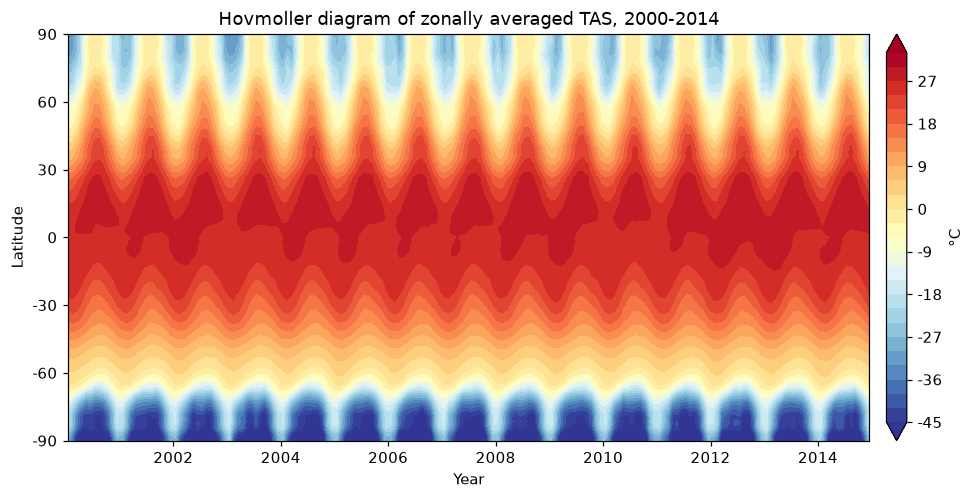

In [36]:
# --- 3.2 plot 5: Hovmoller diagram --------------------------------------
# Time on the vertical axis, latitude on the horizontal one, longitude
# averaged: the seasonal march of the thermal equator and the year-to-year
# anomalies both become visible at once.
hov = tas_c.mean("lon").transpose("lat", "time")

fig, ax = plt.subplots(figsize=(10.0, 4.8))
cf = ax.contourf(tnum, hov.lat, hov, levels=np.arange(-45, 36, 3),
                 cmap="RdYlBu_r", extend="both")
ax.set_xlabel("Year")
ax.set_ylabel("Latitude")
ax.set_title("Hovmoller diagram of zonally averaged TAS, 2000-2014")
ax.grid(False)
ax.set_yticks([-90, -60, -30, 0, 30, 60, 90])
cb = fig.colorbar(cf, ax=ax, pad=0.02, fraction=0.04)
cb.set_label("$\\degree$C")
fig.savefig(os.path.join(FIG_DIR, "p3_2e_hovmoller.png"))
plt.show()

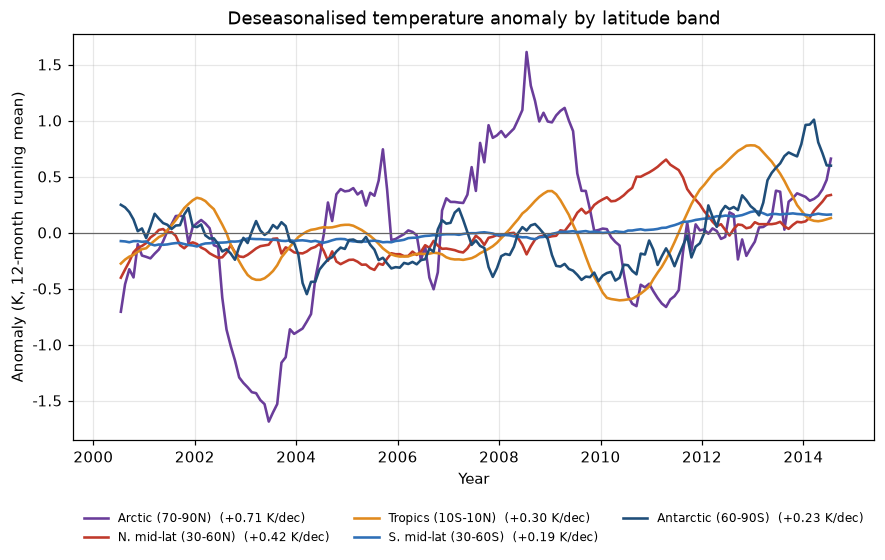

In [37]:
# --- 3.2 plot 6: regional warming rates ---------------------------------
# Six boxes, one per continent / ocean basin, compared on the same axis.  The
# differences between them are the reason a single global number is not enough.
REGIONS = [
    ("Arctic (70-90N)", 70, 90, 0, 360, "#6a3d9a"),
    ("N. mid-lat (30-60N)", 30, 60, 0, 360, "#c0392b"),
    ("Tropics (10S-10N)", -10, 10, 0, 360, "#e08a1e"),
    ("S. mid-lat (30-60S)", -60, -30, 0, 360, "#2e6fb7"),
    ("Antarctic (60-90S)", -90, -60, 0, 360, "#1f4e79"),
]

fig, ax = plt.subplots(figsize=(9.4, 4.8))
for lab, s, n, x0, x1, col in REGIONS:
    box = tas_c.sel(lat=slice(s, n))
    wb = np.cos(np.deg2rad(box.lat))
    sb = box.weighted(wb).mean(dim=("lat", "lon"))
    cb_ = sb.groupby("time.month") - sb.groupby("time.month").mean("time")
    slope = np.polyfit(month_index, cb_.values, 1)[0] * 120
    # a 12-month running mean is used for display only: the annual cycle is
    # already removed, but month-to-month weather noise still hides the trend
    smooth = cb_.rolling(time=12, center=True, min_periods=12).mean()
    ax.plot(tnum, smooth, "-", lw=1.7, color=col,
            label="%s  (%+.2f K/dec)" % (lab, slope))
ax.axhline(0, color="0.4", lw=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("Anomaly (K, 12-month running mean)")
ax.set_title("Deseasonalised temperature anomaly by latitude band")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False,
          fontsize=8, ncol=3)
ax.grid(True, alpha=0.3)
ax.set_xlim(1999.6, 2015.4)
fig.savefig(os.path.join(FIG_DIR, "p3_2f_regional_series.png"))
plt.show()

In [38]:
# --- 3.2 summary ----------------------------------------------------------
band_amp = {}
for s, n in [(-60, -30), (0, 30), (60, 90)]:
    band = tas_c.sel(lat=slice(s, n))
    wb = np.cos(np.deg2rad(band.lat))
    sb = band.weighted(wb).mean(dim=("lat", "lon")).groupby("time.month").mean("time")
    band_amp[(s, n)] = float(sb.max() - sb.min())

band_trend = {}
for s, n in [(70, 90), (-90, -60)]:
    band = tas_c.sel(lat=slice(s, n))
    wb = np.cos(np.deg2rad(band.lat))
    sb = band.weighted(wb).mean(dim=("lat", "lon"))
    cb_ = (sb.groupby("time.month") - sb.groupby("time.month").mean("time")).values
    band_trend[(s, n)] = float(np.polyfit(month_index, cb_, 1)[0] * 120)

print("summary of the six plots:")
print("  1 time-mean field      : %.1f .. %.1f degC"
      % (float(mean_field.min()), float(mean_field.max())))
print("  2 annual cycle by band : amplitudes %.1f / %.1f / %.1f K"
      % (band_amp[(-60, -30)], band_amp[(0, 30)], band_amp[(60, 90)]))
print("  3 zonal profile        : trend range %.2f .. %.2f K/decade"
      % (float(zonal_trend.min()) * 120, float(zonal_trend.max()) * 120))
print("  4 trend pattern        : %.2f .. %.2f K/decade"
      % (float(trend.min()), float(trend.max())))
print("  5 Hovmoller            : %d months x %d latitudes"
      % (hov.sizes["time"], hov.sizes["lat"]))
print("  6 regional series      : Arctic %+.2f, Antarctic %+.2f K/decade"
      % (band_trend[(70, 90)], band_trend[(-90, -60)]))

ds_tas.close()

summary of the six plots:
  1 time-mean field      : -51.9 .. 32.2 degC
  2 annual cycle by band : amplitudes 5.2 / 4.7 / 26.3 K
  3 zonal profile        : trend range 0.15 .. 1.20 K/decade
  4 trend pattern        : -1.13 .. 2.20 K/decade
  5 Hovmoller            : 180 months x 192 latitudes
  6 regional series      : Arctic +0.71, Antarctic +0.23 K/decade
